
# Análisis Exploratorio del Discurso de Género en la Administración Trump (2025-2026)

**Proyecto:** VoxiTech Lab AI — Discurso sobre género, familia y sexualidad  
**Objeto de estudio:** Discursos, órdenes ejecutivas, proclamas y comunicados de la segunda presidencia de Donald J. Trump  
**Corpus:** 12 documentos oficiales de la Casa Blanca (White House), 51 unidades de análisis, 9.908 palabras  
**Enfoque:** Análisis de discurso cualitativo con apoyo de técnicas de procesamiento de lenguaje natural (NLP)

## Marco teórico

Este cuaderno explora cómo se construye el discurso sobre género, familia y sexualidad en los documentos oficiales de la administración Trump durante su segundo mandato. El análisis parte del supuesto de que el lenguaje político no solo describe la realidad, sino que la constituyen: al nombrar, categorizar y jerarquizar los cuerpos, las familias y las identidades, el discurso produce efectos materiales en la vida de las personas (Foucault, 1971; Fairclough, 1995).

El corpus analizado incluye órdenes ejecutivas, proclamas, fichas informativas (*fact sheets*), comunicados (*releases*) y declaraciones (*remarks*) publicadas en *whitehouse.gov* entre enero de 2025 y junio de 2026. Todos los documentos fueron descargados, limpiados, segmentados y codificados mediante el pipeline reproducible de VoxiTech Lab AI.

> **Nota ética:** El análisis se realiza con fines académicos de investigación en discurso político. Las citas textuales se reproducen con el único propósito de ilustrar los hallazgos del análisis y se atribuyen debidamente a sus fuentes originales conforme a las normas APA 7.



## Citas textuales seleccionadas del corpus

A continuación se presentan citas textuales largas extraídas directamente del corpus ingestido. Estas frases ilustran los marcos discursivos centrales sobre género, familia y sexualidad identificados en el análisis. Cada cita incluye su referencia completa en normas APA 7.

### 1. Sobre la ideología de género y la realidad biológica (Orden Ejecutiva, 20 de enero de 2025)

> “Across the country, ideologues who deny the biological reality of sex have increasingly used legal and other socially coercive means to permit men to self-identify as women and gain access to intimate single-sex spaces and activities designed for women, from women's domestic abuse shelters to women's workplace showers.”

(Trump, 2025, Sec. 1)

### 2. Sobre la definición de “ideología de género” (Orden Ejecutiva, 20 de enero de 2025)

> “Gender ideology replaces the biological category of sex with an ever-shifting concept of self-assessed gender identity, permitting the false claim that males can identify as and thus become women and vice versa, and requiring all institutions of society to regard this false claim as true.”

(Trump, 2025, Sec. 2(f))

### 3. Sobre los deportes femeninos (Orden Ejecutiva, 5 de febrero de 2025)

> “In recent years, many educational institutions and athletic associations have allowed men to compete in women's sports. This is demeaning, unfair, and dangerous to women and girls, and denies women and girls the equal opportunity to participate and excel in competitive sports.”

(Trump, 2025, Sec. 1)

### 4. Sobre la participación de personas trans en deportes (Orden Ejecutiva, 5 de febrero de 2025)

> “Many sport-specific governing bodies have no official position or requirements regarding trans-identifying athletes. Others allow men to compete in women's categories if these men reduce the testosterone in their bodies below certain levels or provide documentation of 'sincerely held' gender identity. These policies are unfair to female athletes and do not protect female safety.”

(Trump, 2025, Sec. 4)

### 5. Sobre la prohibición de financiamiento para procedimientos de reasignación de género en menores (Comunicado, 30 de junio de 2026)

> “Banning federal funding, sponsorship, and promotion of child gender mutilation, resulting in more than 40 hospitals and health systems across the country stopping or suspending child mutilation programs.”

(The White House, 2026b)

### 6. Sobre la maternidad y la fortaleza femenina (Primera Dama Melania Trump, 8 de mayo de 2025)

> “Motherhood: The life-changing event that makes women invincible and exposed at the same time.”

(Trump, 2025j)

Estas citas serán retomadas a lo largo del análisis cualitativo para ilustrar los patrones temáticos detectados automáticamente por el diccionario de género y familia del proyecto.


In [30]:

# Configuración inicial y carga de datos
# --------------------------------------

import pandas as pd
import numpy as np
import re
from pathlib import Path
from collections import Counter

# Visualización
import matplotlib
# Nota: no se fuerza Agg para permitir visualización interactiva en el notebook
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
import networkx as nx

# Configuración de estilo para publicación académica
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 0  # Sin título dentro de la figura (APA 7)
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.dpi"] = 300

# Directorios (robusto a que el notebook se ejecute desde la carpeta notebooks/)
_cwd = Path.cwd()
PROJECT_ROOT = _cwd.parent if _cwd.name == "notebooks" else _cwd
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
OUTPUTS_NOTEBOOK = PROJECT_ROOT / "outputs" / "analisis" / "notebook"
OUTPUTS_NOTEBOOK.mkdir(parents=True, exist_ok=True)

print("Directorio de salidas:", OUTPUTS_NOTEBOOK.resolve())

# Cargar unidades de análisis y menciones temáticas
units_path = DATA_PROCESSED / "units.parquet"
mentions_path = DATA_PROCESSED / "mentions.parquet"

units_df = pd.read_parquet(units_path)
mentions_df = pd.read_parquet(mentions_path)

print(f"Unidades de análisis: {len(units_df)}")
print(f"Menciones temáticas: {len(mentions_df)}")
print(f"Palabras totales: {units_df['word_count'].sum():,}")
print(f"Temas detectados: {mentions_df['theme'].nunique()}")
print(f"Unidades con menciones: {mentions_df['unit_id'].nunique()}")


Directorio de salidas: C:\Users\qluis\Documents\Proyectos\voxitech\outputs\analisis\notebook
Unidades de análisis: 51
Menciones temáticas: 543
Palabras totales: 9,908
Temas detectados: 13
Unidades con menciones: 51


In [31]:

# Estadísticas descriptivas del corpus
# ------------------------------------

print("=== Documentos por tipo ===")
print(units_df["document_type"].value_counts())
print()

print("=== Documentos por fecha ===")
print(units_df["date"].value_counts().sort_index())
print()

print("=== Longitud de unidades (palabras) ===")
print(units_df["word_count"].describe())
print()

top_units = units_df.nlargest(5, "word_count")[["unit_id", "document_type", "date", "speaker", "word_count"]]
print("=== Unidades más extensas ===")
print(top_units.to_string(index=False))


=== Documentos por tipo ===
document_type
executive_order    34
fact_sheet          7
proclamation        6
release             2
remarks             2
Name: count, dtype: int64

=== Documentos por fecha ===
date
2025-01-20    15
2025-01-21     8
2025-01-22     3
2025-01-27     2
2025-01-28     5
2025-02-05     6
2025-03-06     3
2025-03-18     2
2025-05-08     2
2026-03-12     3
2026-06-30     2
Name: count, dtype: int64

=== Longitud de unidades (palabras) ===
count     51.000000
mean     194.274510
std       27.566703
min       92.000000
25%      200.000000
50%      200.000000
75%      200.000000
max      248.000000
Name: word_count, dtype: float64

=== Unidades más extensas ===
                             unit_id   document_type       date         speaker  word_count
309ac685-cd30-512a-bc00-6f572b0b7148         remarks 2025-05-08   Melania Trump         248
1a8189cb-4d1a-567b-ad55-9bc65a4f0d7b      fact_sheet 2025-01-27 The White House         247
0942b65d-2f05-52a6-8e88-228879d00


## Figura 1. Frecuencia de menciones temáticas por categoría

El gráfico de barras muestra el número total de menciones detectadas por cada categoría temática del diccionario de género y familia. Permite identificar qué ejes del discurso son más intensos en el corpus analizado.

La imagen se exporta automáticamente a `outputs/analisis/notebook/`.


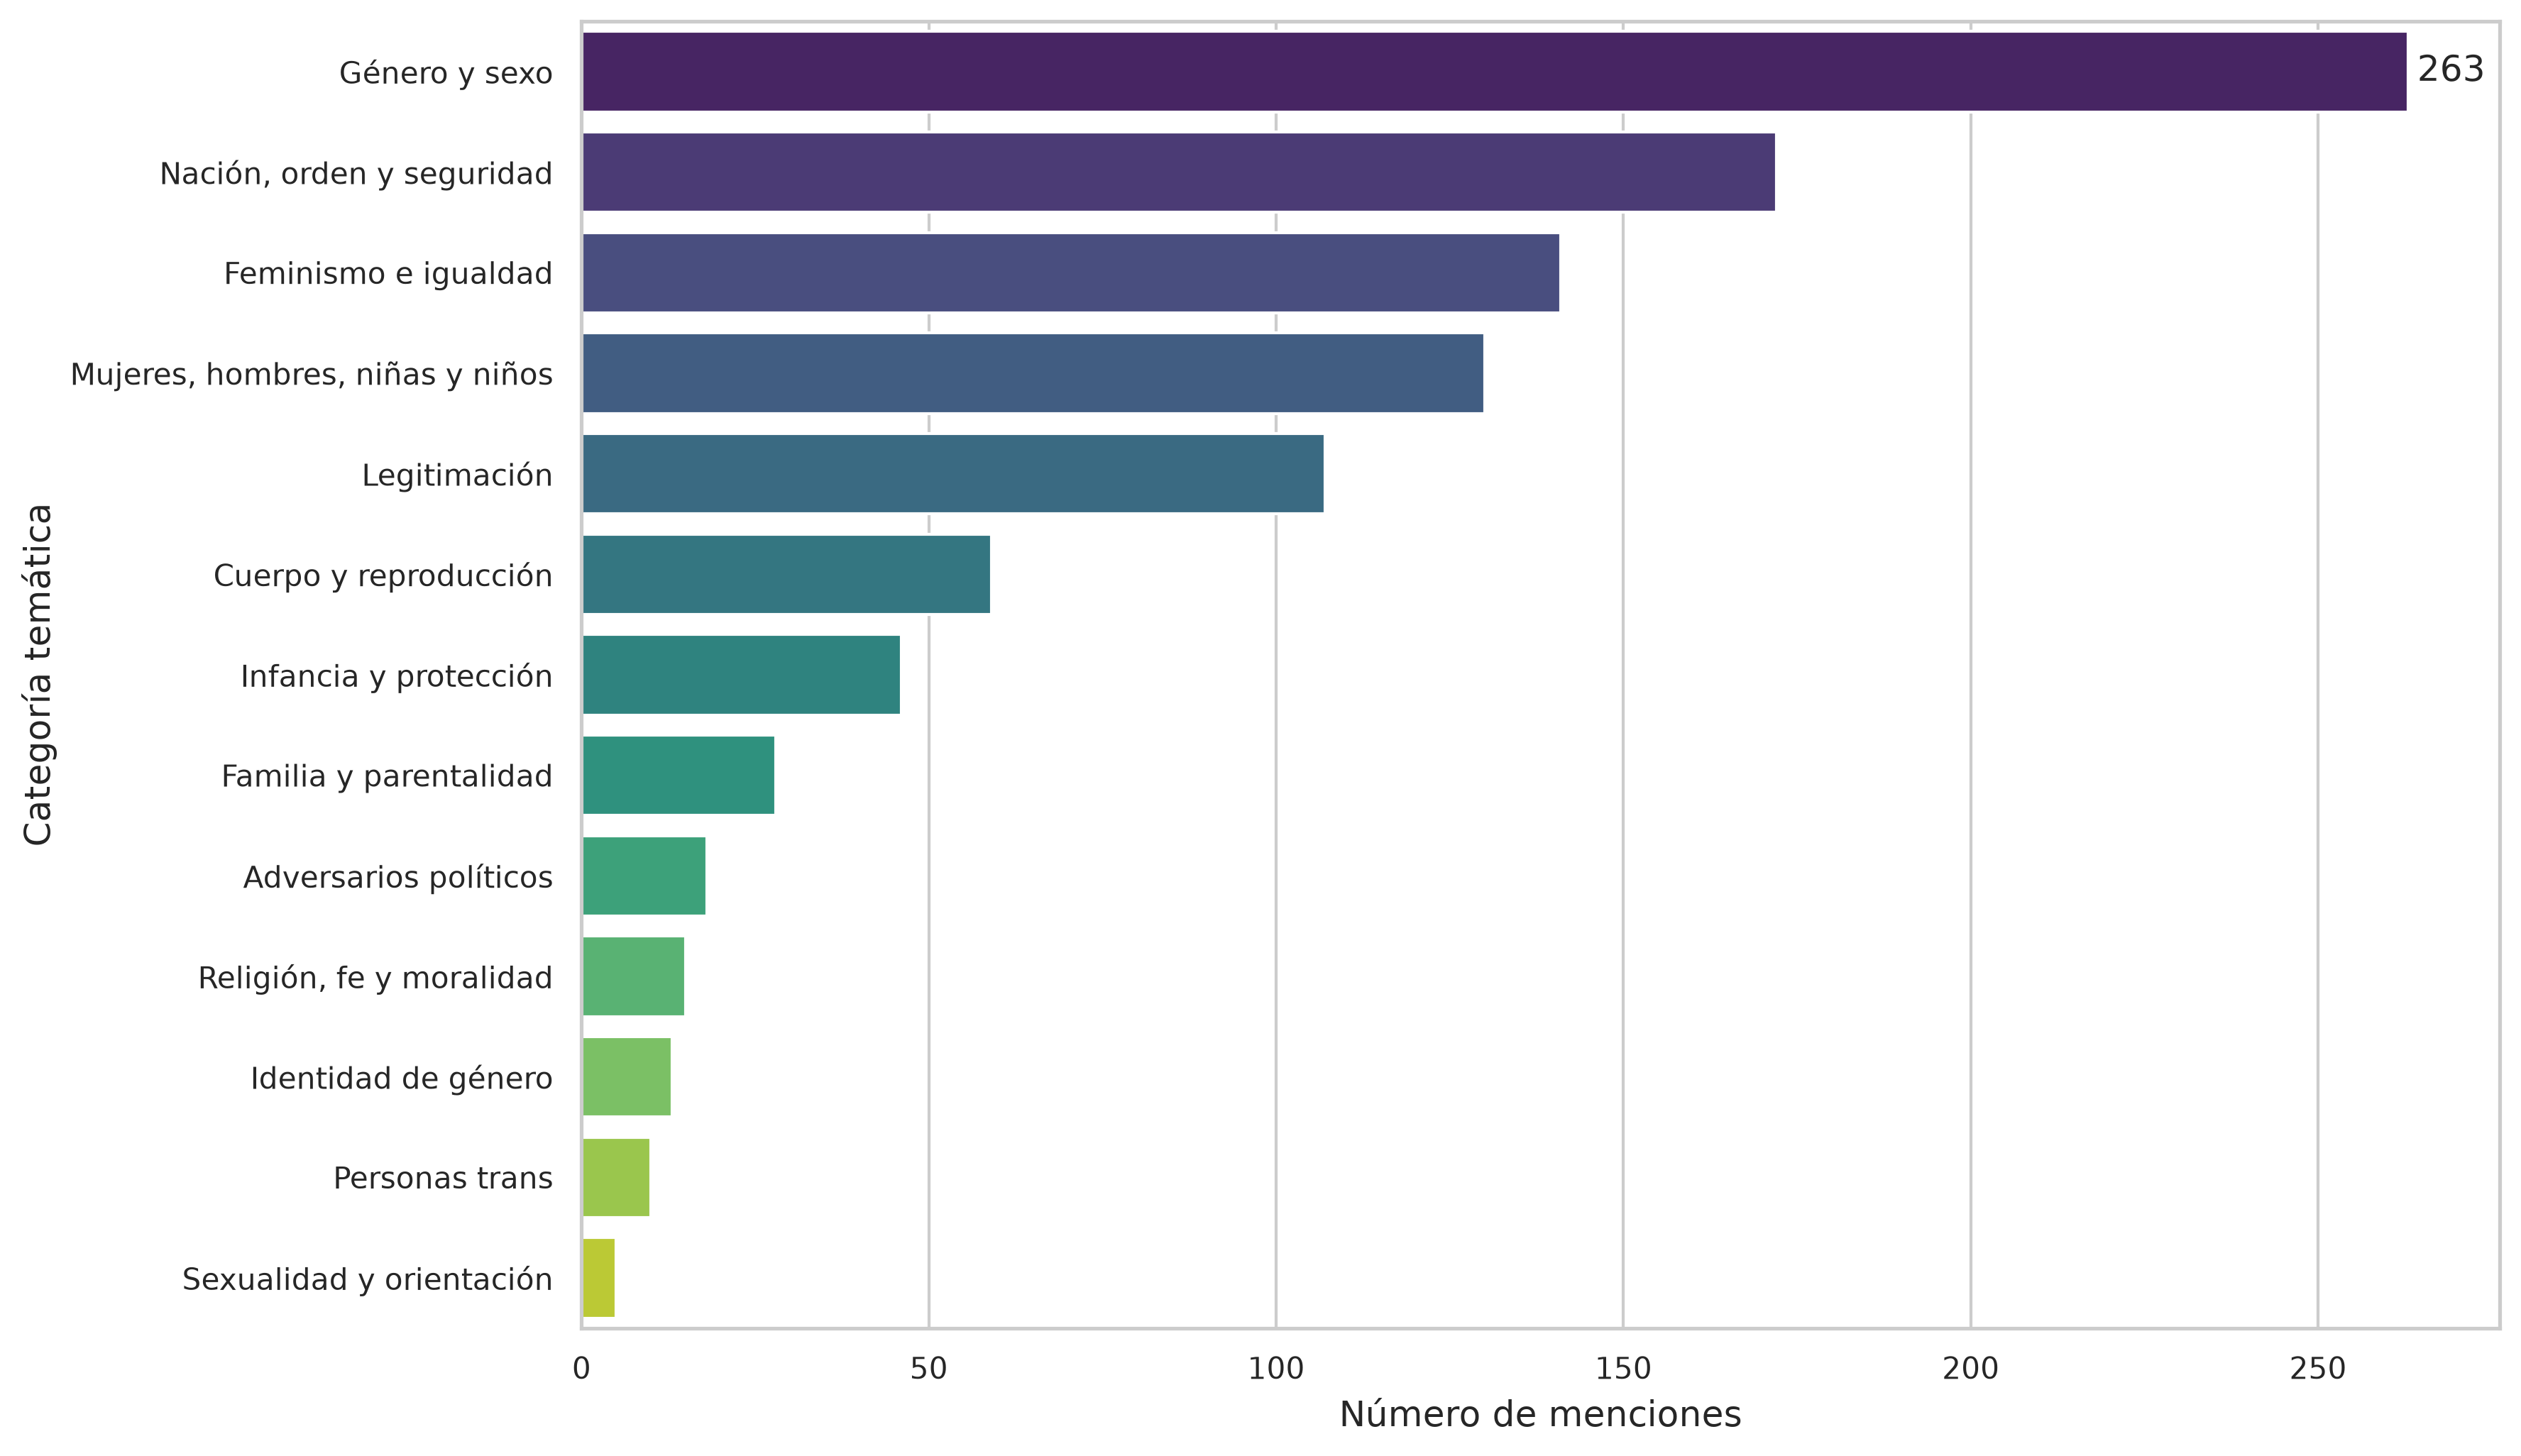

In [32]:

# --- Figura 1: Frecuencia de menciones por tema (sin título, estilo APA 7) ---

theme_freq = (
    mentions_df.groupby("theme")
    .agg(total_mentions=("frequency", "sum"), total_units=("unit_id", "nunique"))
    .reset_index()
    .sort_values("total_mentions", ascending=False)
)

theme_labels = {
    "genero_y_sexo": "Género y sexo",
    "nacion_orden_seguridad": "Nación, orden y seguridad",
    "feminismo_e_igualdad": "Feminismo e igualdad",
    "mujer_hombre_ninas_ninos": "Mujeres, hombres, niñas y niños",
    "legitimacion": "Legitimación",
    "cuerpo_y_reproduccion": "Cuerpo y reproducción",
    "infancia_y_proteccion": "Infancia y protección",
    "familia_y_parentalidad": "Familia y parentalidad",
    "adversarios_politicos": "Adversarios políticos",
    "religion_fe_moralidad": "Religión, fe y moralidad",
    "identidad_de_genero": "Identidad de género",
    "personas_trans": "Personas trans",
    "sexualidad_y_orientacion": "Sexualidad y orientación",
}

theme_freq["theme_label"] = theme_freq["theme"].map(theme_labels).fillna(theme_freq["theme"])

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=theme_freq,
    x="total_mentions",
    y="theme_label",
    hue="theme_label",
    palette="viridis",
    orient="h",
    legend=False,
    ax=ax,
)
ax.set_xlabel("Número de menciones")
ax.set_ylabel("Categoría temática")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
plt.tight_layout()

fig_path = OUTPUTS_NOTEBOOK / "figura_01_frecuencia_por_tema.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()



## Figura 2. Densidad promedio de menciones por tema

La densidad mide el número de menciones por cada 1.000 palabras de cada unidad, lo que permite comparar la intensidad temática independientemente de la longitud del documento.

La imagen se exporta automáticamente a `outputs/analisis/notebook/`.


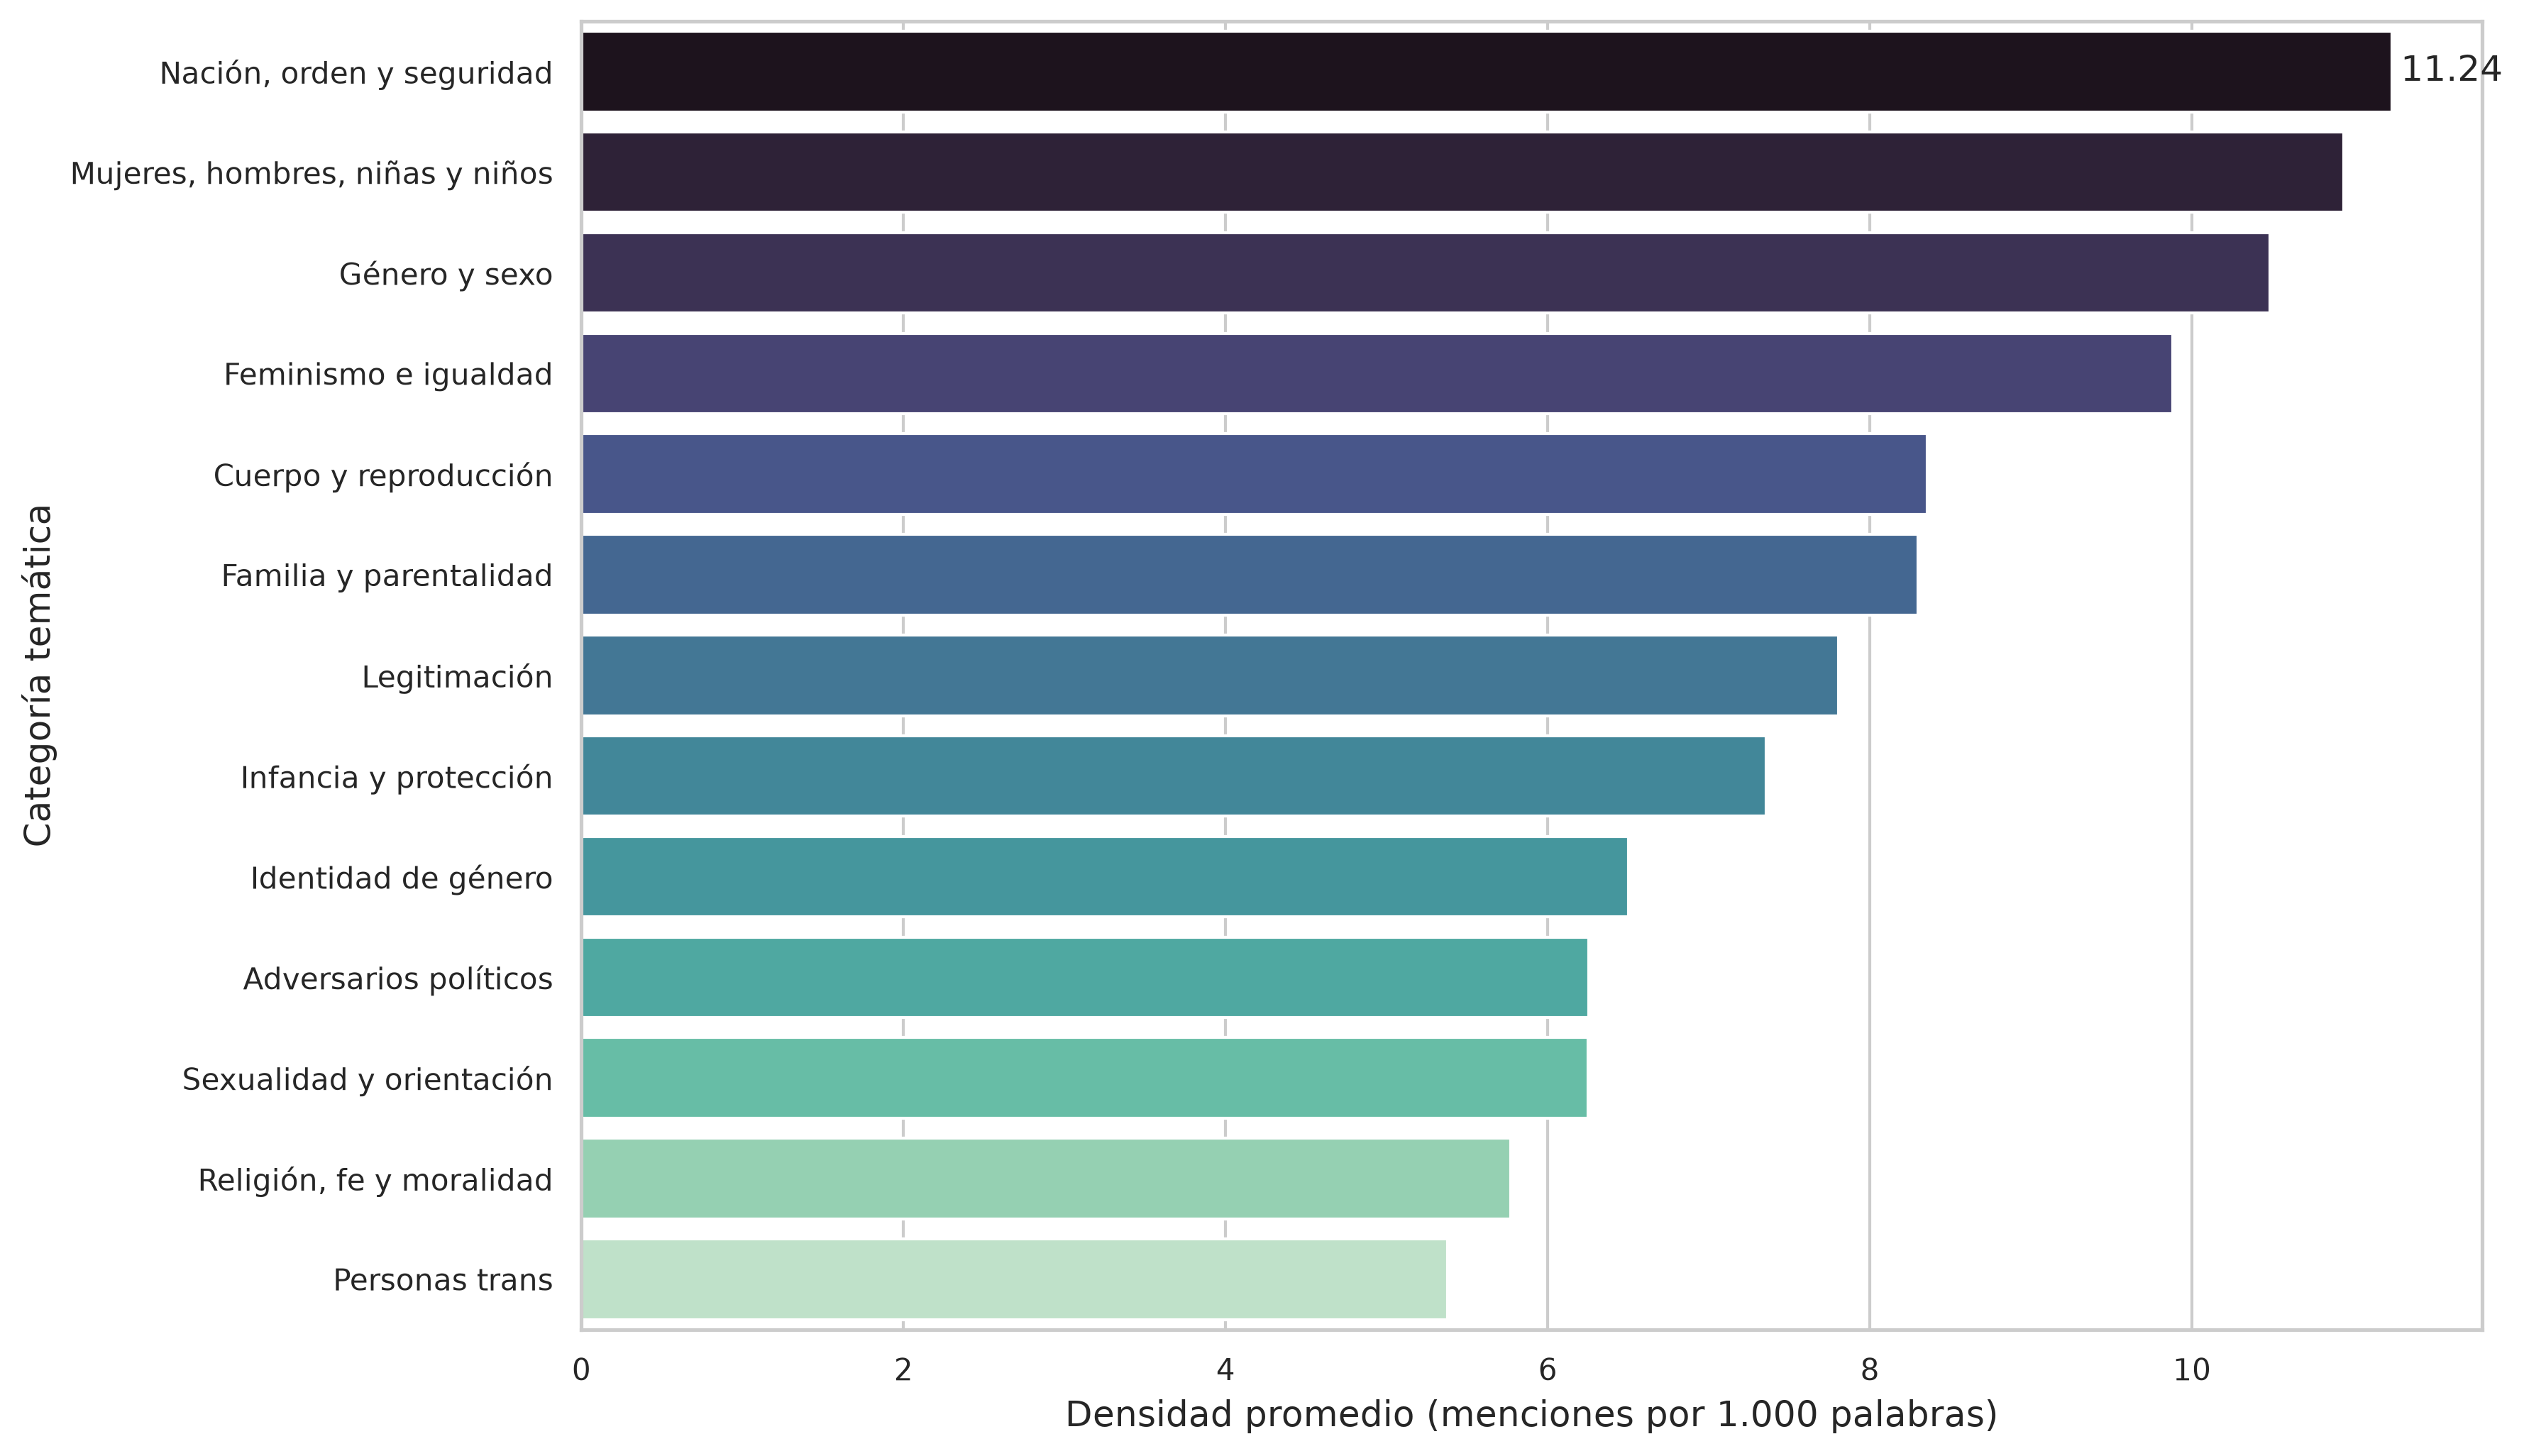

Exportado: c:\Users\qluis\Documents\Proyectos\voxitech\outputs\analisis\notebook\figura_02_densidad_por_tema.png


In [33]:

# --- Figura 2: Densidad promedio por tema (sin título, estilo APA 7) ---

theme_density = (
    mentions_df.groupby("theme")["density_per_1k_words"]
    .mean()
    .reset_index()
    .rename(columns={"density_per_1k_words": "avg_density_per_1k"})
    .sort_values("avg_density_per_1k", ascending=False)
)
theme_density["theme_label"] = theme_density["theme"].map(theme_labels).fillna(theme_density["theme"])

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=theme_density,
    x="avg_density_per_1k",
    y="theme_label",
    hue="theme_label",
    palette="mako",
    orient="h",
    legend=False,
    ax=ax,
)
ax.set_xlabel("Densidad promedio (menciones por 1.000 palabras)")
ax.set_ylabel("Categoría temática")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.tight_layout()

fig_path = OUTPUTS_NOTEBOOK / "figura_02_densidad_por_tema.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print("Exportado:", fig_path)



## Figura 3. Nube de palabras del corpus

La nube de palabras visualiza los términos más frecuentes del corpus limpio, descartando palabras vacías (*stopwords*) en inglés. El tamaño de cada palabra es proporcional a su frecuencia en el corpus. Esta figura ofrece una visión cualitativa rápida de los conceptos centrales del discurso.

La imagen se exporta automáticamente a `outputs/analisis/notebook/` con alta resolución (300 dpi) para su inserción en publicaciones académicas.


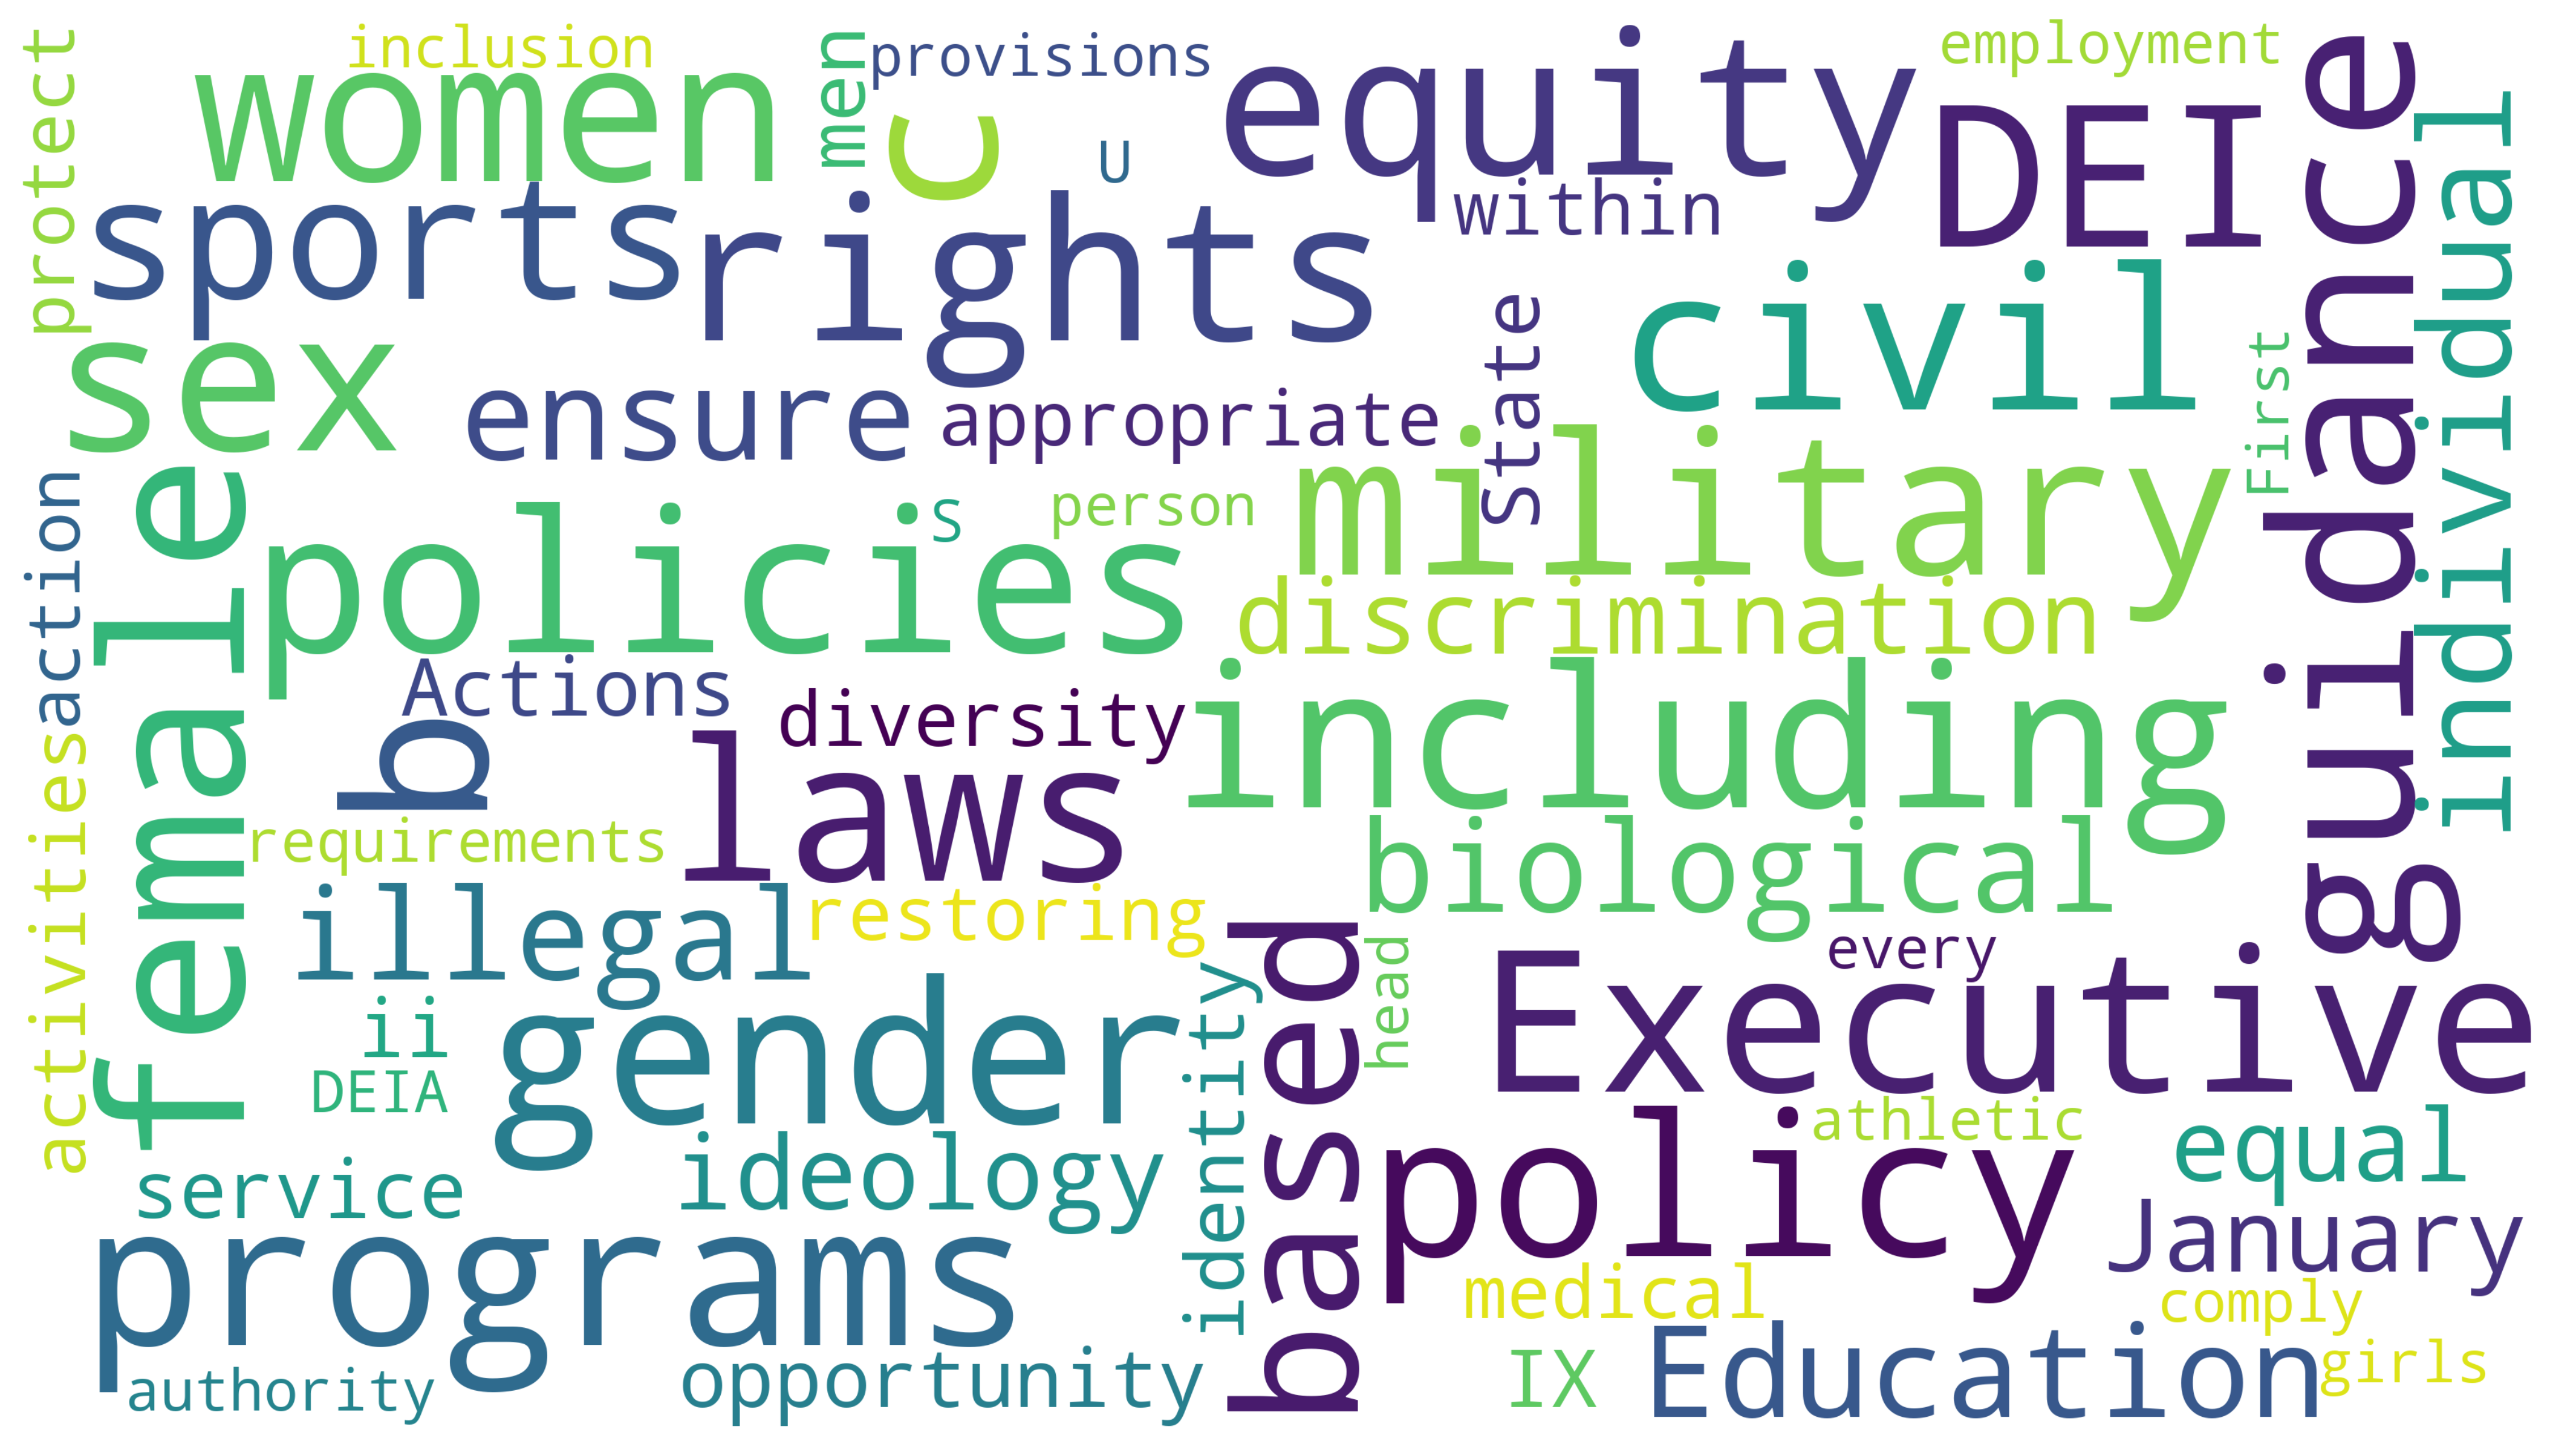

Exportado: c:\Users\qluis\Documents\Proyectos\voxitech\outputs\analisis\notebook\figura_03_nube_de_palabras.png


In [34]:

# --- Figura 3: Nube de palabras del corpus (estilo académico, sin título) ---

corpus_text = " ".join(units_df["text"].astype(str))

custom_stopwords = set(STOPWORDS)
custom_stopwords.update({
    "the", "and", "to", "of", "a", "in", "is", "it", "that", "for", "on", "with",
    "as", "by", "be", "are", "this", "or", "from", "was", "will", "have", "has",
    "had", "not", "but", "they", "their", "there", "which", "you", "your", "we",
    "our", "us", "he", "she", "him", "her", "his", "its", "an", "at", "can", "could",
    "would", "should", "may", "might", "must", "shall", "do", "does", "did", "done",
    "white", "house", "president", "trump", "administration", "federal",
    "government", "united", "states", "america", "american", "order", "section",
    "sec", "shall", "act", "law", "code", "title", "department", "agency", "agencies",
    "office", "director", "secretary", "attorney", "general", "therefore",
    "hereby", "pursuant", "subsection", "paragraph"
})

# Nube de palabras: tamaño estrictamente proporcional a la frecuencia
# relative_scaling=0 -> el tamaño depende SOLO de la frecuencia (no hay suavizado)
# Las palabras más frecuentes quedan más grandes y el algoritmo las coloca en el centro
wordcloud = WordCloud(
    width=1800,
    height=1000,
    background_color="white",
    stopwords=custom_stopwords,
    max_words=60,  # menos palabras para mayor contraste entre las principales
    colormap="viridis",
    collocations=False,
    normalize_plurals=False,
    prefer_horizontal=0.7,
    min_font_size=10,   # palabras pequeñas para las menos frecuentes
    max_font_size=140,  # palabras grandes para las más frecuentes
    relative_scaling=0,  # tamaño estrictamente proporcional a la frecuencia
    scale=2,             # mayor resolución
    margin=2,            # menos espacio entre palabras para mayor densidad
    random_state=42,
).generate(corpus_text)

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(wordcloud, interpolation="bilinear")
ax.axis("off")
plt.tight_layout(pad=0)

fig_path = OUTPUTS_NOTEBOOK / "figura_03_nube_de_palabras.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight", pad_inches=0.1)
plt.show()
print("Exportado:", fig_path)



### Las 10 palabras más frecuentes del corpus

| Palabra | Apariciones |
|---------|-------------|
| women | 83 |
| sex | 51 |
| executive | 47 |
| dei | 43 |
| policy | 39 |
| gender | 37 |
| military | 33 |
| policies | 32 |
| rights | 31 |
| guidance | 29 |

*Frecuencias calculadas sobre el corpus limpio (51 unidades, 9.908 palabras), excluyendo stopwords y palabras de menos de 3 letras.*



## Figura 4. Red de co-ocurrencia de términos clave

Esta figura muestra una red en la que los **nodos** representan términos clave del diccionario de género y familia, y las **aristas** representan la co-ocurrencia de dos términos dentro de la misma unidad de análisis. El grosor de cada arista es proporcional a la frecuencia de co-ocurrencia.

Esta visualización permite analizar de forma cualitativa la **interacción entre palabras y conceptos**: qué términos tienden a aparecer juntos, formando clústeres semánticos que revelan los marcos discursivos subyacentes.

La imagen se exporta automáticamente a `outputs/analisis/notebook/` con alta resolución para su inserción en publicaciones académicas.


Pares de co-ocurrencia totales: 576
Pares con >= 2 co-ocurrencias: 370


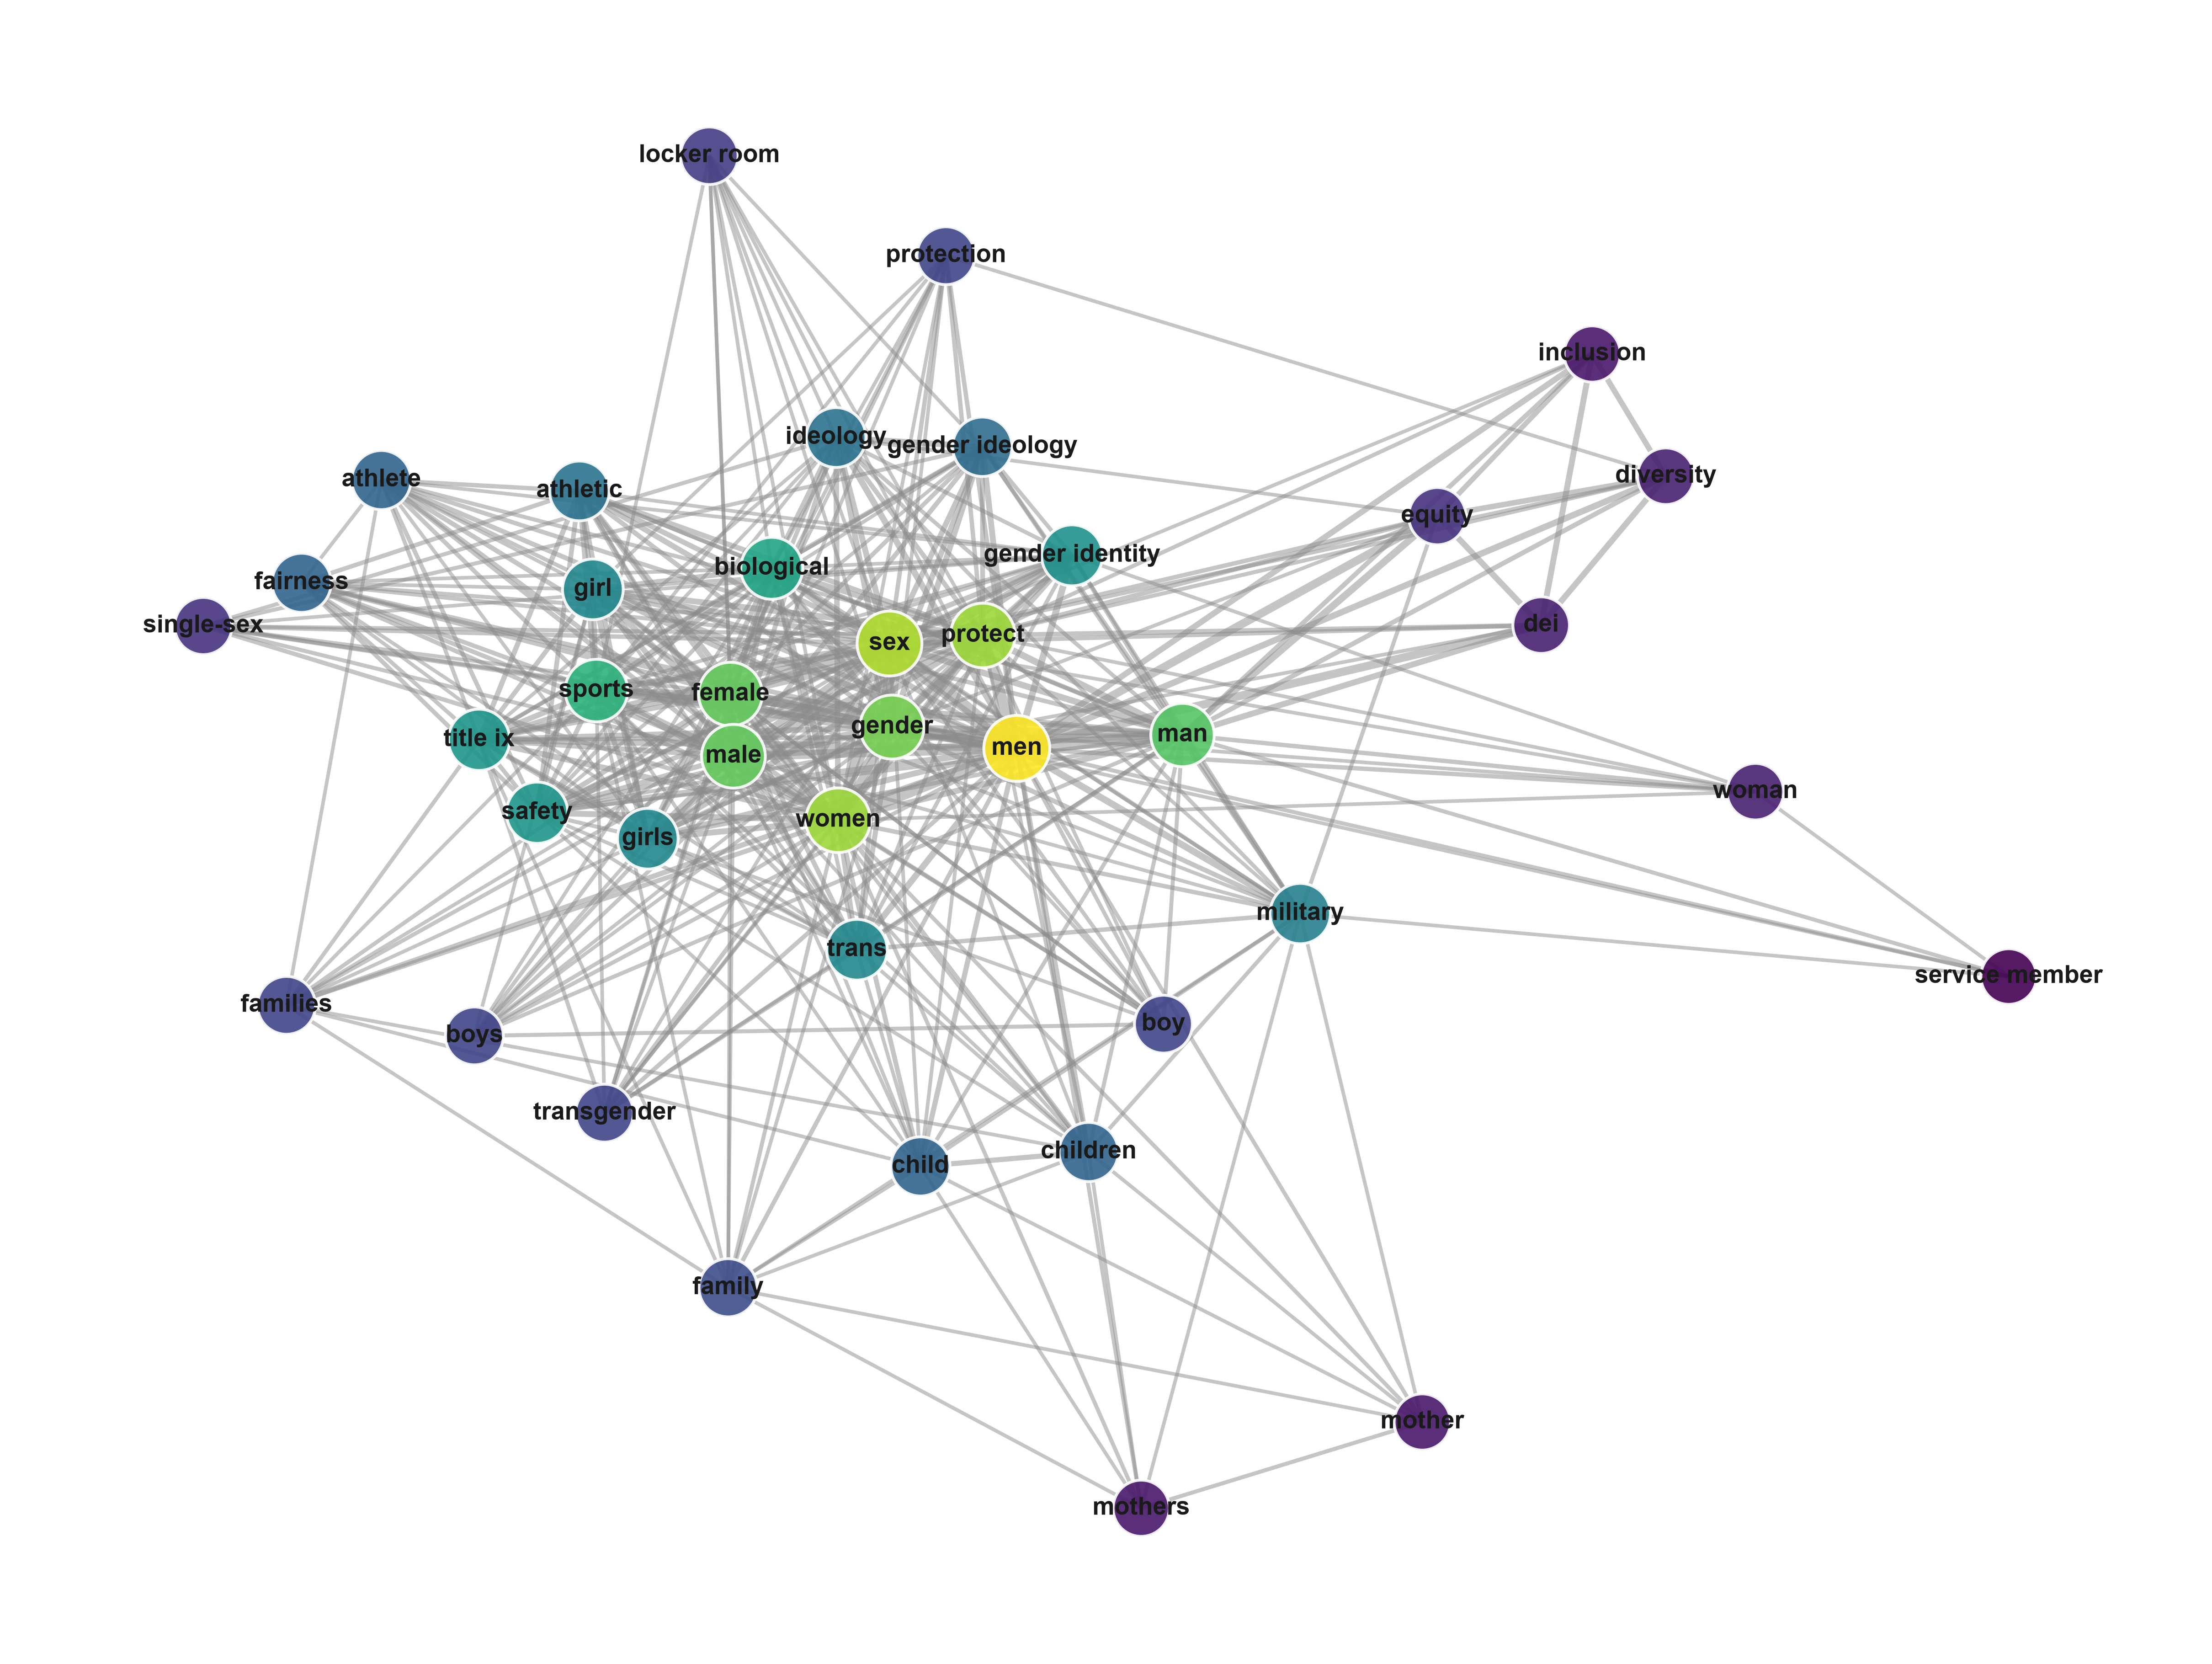

Exportado: c:\Users\qluis\Documents\Proyectos\voxitech\outputs\analisis\notebook\figura_04_red_coocurrencia.png
Nodos en la red: 40
Aristas en la red: 370


In [35]:

# --- Figura 4: Red de co-ocurrencia de términos clave (mejorada para académico) ---

from collections import defaultdict

key_terms = [
    "women", "woman", "men", "man", "girls", "girl", "boys", "boy",
    "female", "male", "sex", "gender", "gender identity", "biological",
    "family", "families", "mother", "mothers", "father", "fathers",
    "sports", "athletic", "athlete", "title ix",
    "transgender", "trans", "ideology", "gender ideology",
    "single-sex", "single sex spaces", "bathroom", "locker room",
    "protection", "protect", "children", "child", "safety", "fairness",
    "dei", "diversity", "equity", "inclusion", "military", "service member"
]

key_terms_lower = [t.lower() for t in key_terms]

co_occurrence = defaultdict(int)

for _, row in units_df.iterrows():
    text = row["text"].lower()
    present_terms = [t for t in key_terms_lower if t in text]
    for i in range(len(present_terms)):
        for j in range(i + 1, len(present_terms)):
            pair = tuple(sorted([present_terms[i], present_terms[j]]))
            co_occurrence[pair] += 1

min_cooccur = 2
filtered_pairs = {pair: count for pair, count in co_occurrence.items() if count >= min_cooccur}

print(f"Pares de co-ocurrencia totales: {len(co_occurrence)}")
print(f"Pares con >= {min_cooccur} co-ocurrencias: {len(filtered_pairs)}")

G = nx.Graph()
for (t1, t2), weight in filtered_pairs.items():
    G.add_edge(t1, t2, weight=weight)

# Tamaño de nodos más grande para legibilidad académica
node_degrees = dict(G.degree())
max_degree = max(node_degrees.values()) if node_degrees else 1
node_sizes = [800 + 400 * (node_degrees[n] / max_degree) for n in G.nodes()]

# Grosor de aristas más visible
edge_weights = [G[u][v]["weight"] for u, v in G.edges()]
max_weight = max(edge_weights) if edge_weights else 1
edge_widths = [1.5 + 5 * (w / max_weight) for w in edge_weights]

# Layout con más espacio entre nodos
pos = nx.spring_layout(G, seed=42, k=1.2, iterations=200)

fig, ax = plt.subplots(figsize=(16, 12))

# Dibujar aristas primero (detrás de nodos)
nx.draw_networkx_edges(G, pos, width=edge_widths, alpha=0.5, edge_color="#8c8c8c", ax=ax)

# Dibujar nodos con colores por grado
node_colors = [node_degrees[n] for n in G.nodes()]
nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap="viridis",
    alpha=0.9,
    linewidths=1.5,
    edgecolors="white",
    ax=ax,
)

# Etiquetas más grandes y con borde para legibilidad
nx.draw_networkx_labels(
    G, pos,
    font_size=13,
    font_family="sans-serif",
    font_weight="bold",
    ax=ax,
)

ax.set_axis_off()
plt.tight_layout(pad=0.2)

fig_path = OUTPUTS_NOTEBOOK / "figura_04_red_coocurrencia.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight", pad_inches=0.1, facecolor="white")
plt.show()
print("Exportado:", fig_path)
print(f"Nodos en la red: {G.number_of_nodes()}")
print(f"Aristas en la red: {G.number_of_edges()}")



## Figura 5. Distribución de longitud de las unidades de análisis

El histograma muestra cuántas palabras contiene cada una de las 51 unidades de análisis segmentadas.

La imagen se exporta automáticamente a `outputs/analisis/notebook/`.


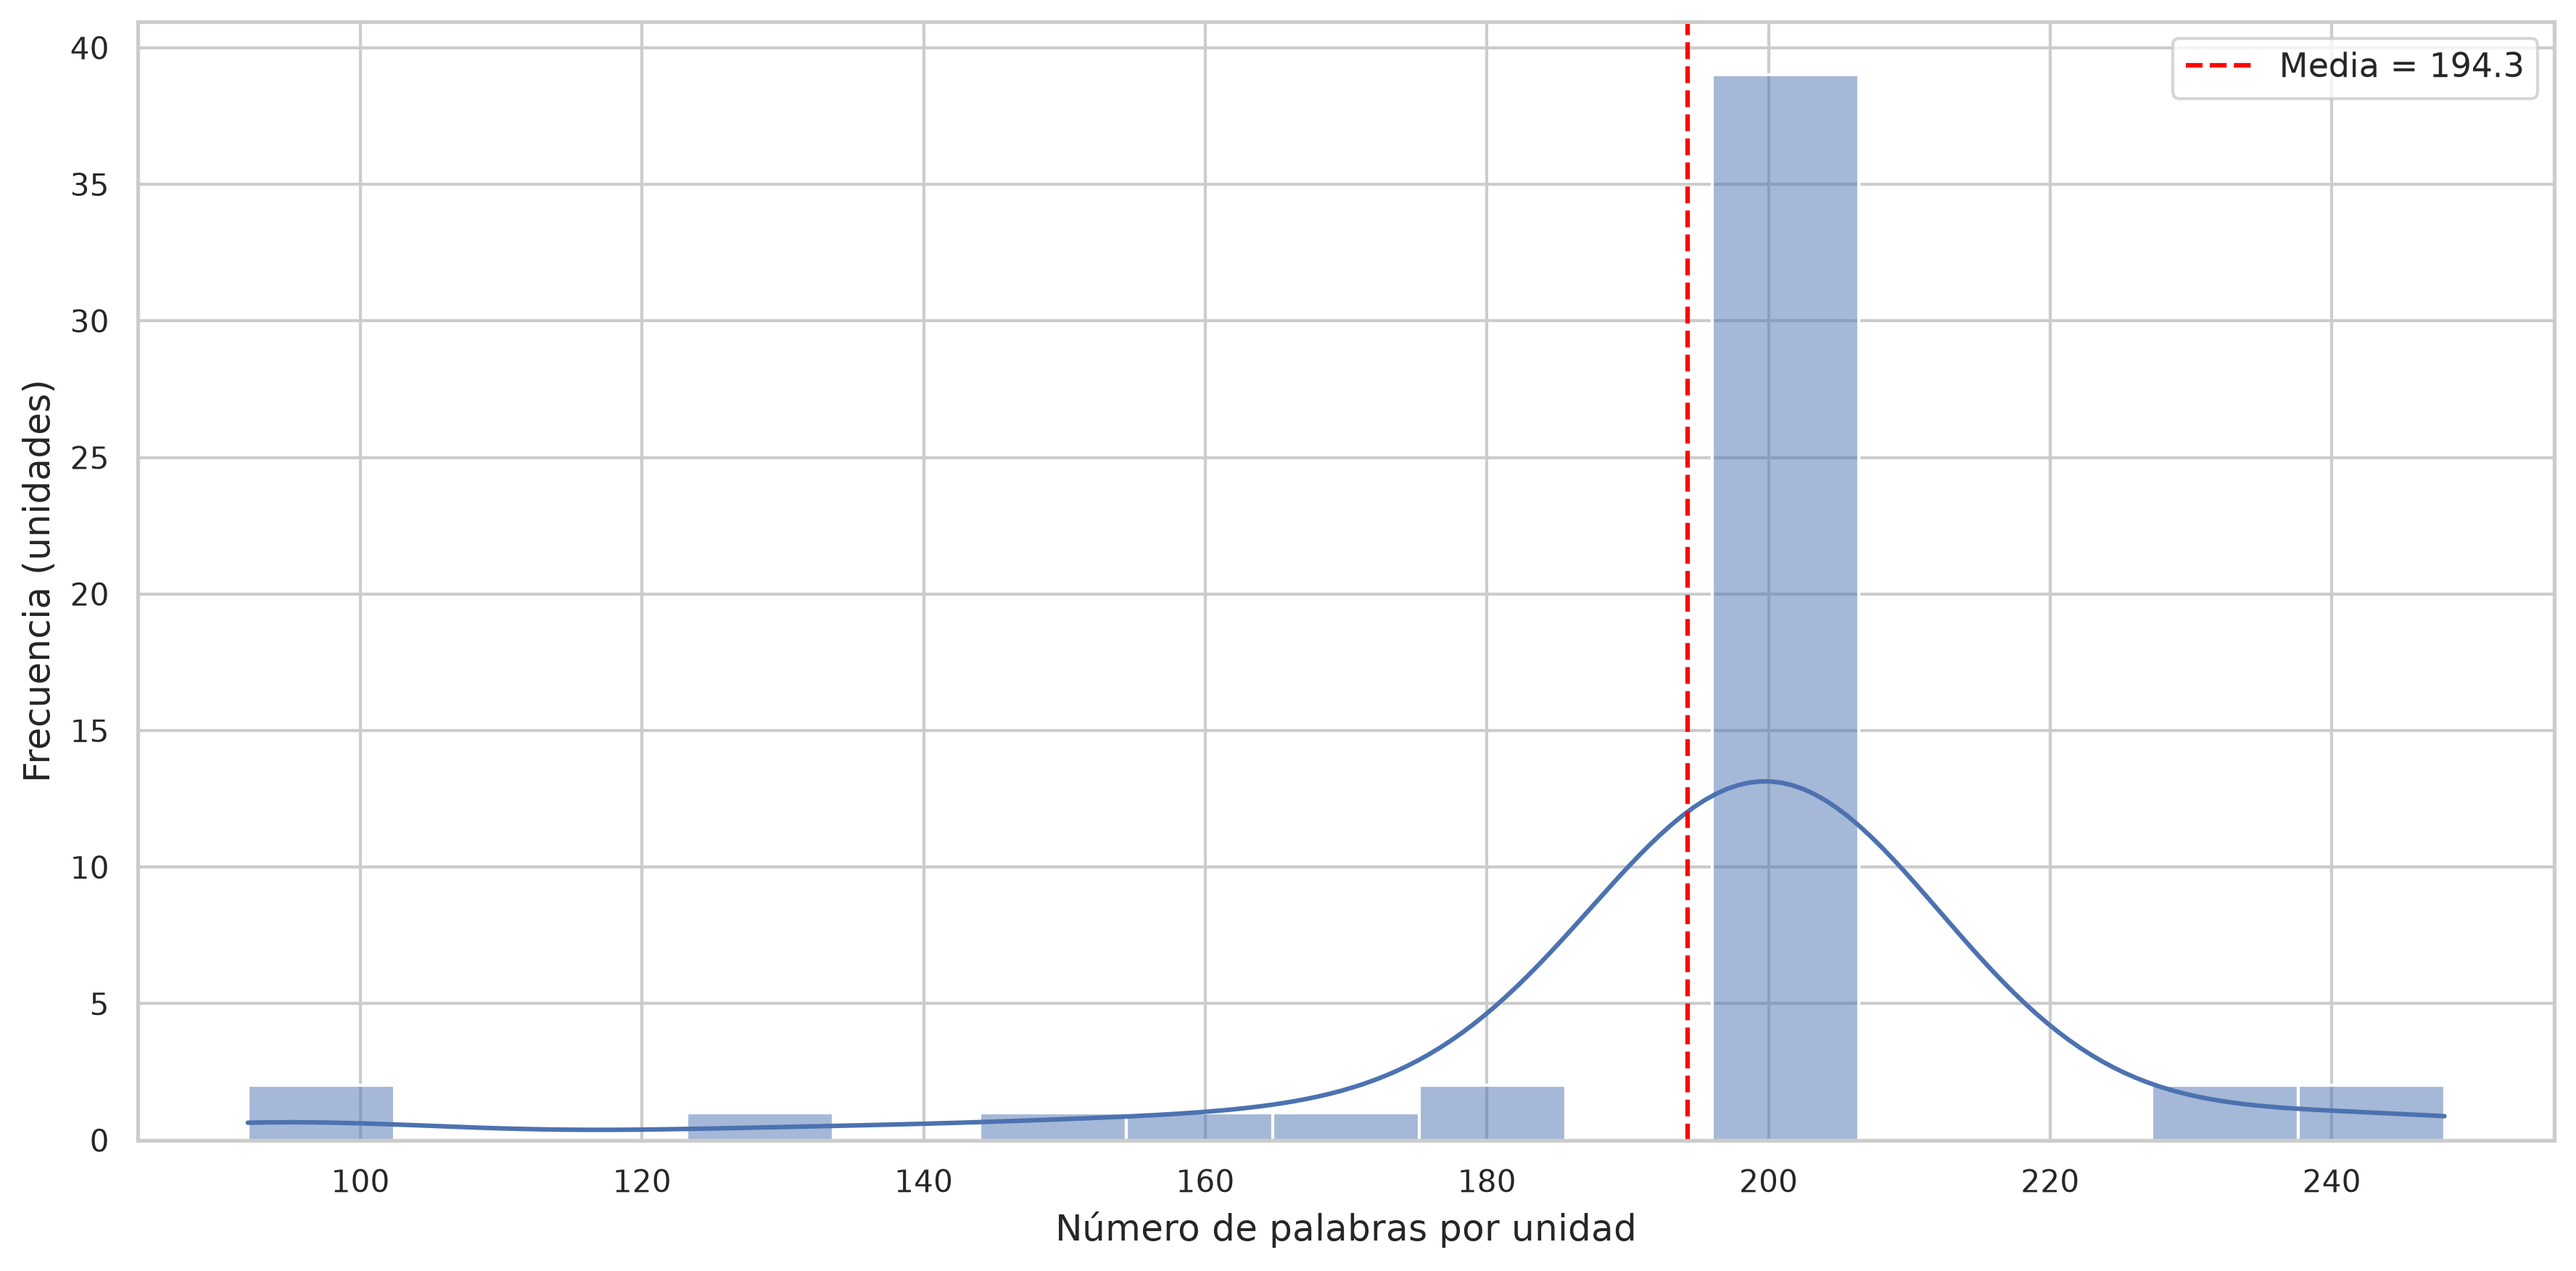

Exportado: c:\Users\qluis\Documents\Proyectos\voxitech\outputs\analisis\notebook\figura_05_distribucion_palabras.png
Media de palabras por unidad: 194.3
Mínimo: 92, Máximo: 248


In [36]:

# --- Figura 5: Distribución de palabras por unidad (sin título, estilo APA 7) ---

fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(
    data=units_df,
    x="word_count",
    bins=15,
    kde=True,
    color="#4c72b0",
    edgecolor="white",
    ax=ax,
)
ax.set_xlabel("Número de palabras por unidad")
ax.set_ylabel("Frecuencia (unidades)")
ax.axvline(units_df["word_count"].mean(), color="red", linestyle="--",
           label=f"Media = {units_df['word_count'].mean():.1f}")
ax.legend()
plt.tight_layout()

fig_path = OUTPUTS_NOTEBOOK / "figura_05_distribucion_palabras.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print("Exportado:", fig_path)
print(f"Media de palabras por unidad: {units_df['word_count'].mean():.1f}")
print(f"Mínimo: {units_df['word_count'].min()}, Máximo: {units_df['word_count'].max()}")



## Figura 6. Matriz de co-ocurrencia de términos clave

A diferencia de la red de nodos (Figura 4), esta matriz muestra de forma literal y sistemática la **co-ocurrencia entre pares de términos** dentro de cada unidad de análisis. Cada celda indica cuántas veces aparecieron juntos los dos términos correspondientes (fila y columna) en una misma unidad. Los valores más altos revelan los vínculos semánticos más fuertes del discurso —por ejemplo, la asociación sistemática entre *women*, *sports* y *biological*, o entre *family*, *children* y *protection*— lo que permite identificar los clústeres discursivos subyacentes con precisión cuantitativa.

La imagen se exporta automáticamente a `outputs/analisis/notebook/` con alta resolución para su inserción en publicaciones académicas.


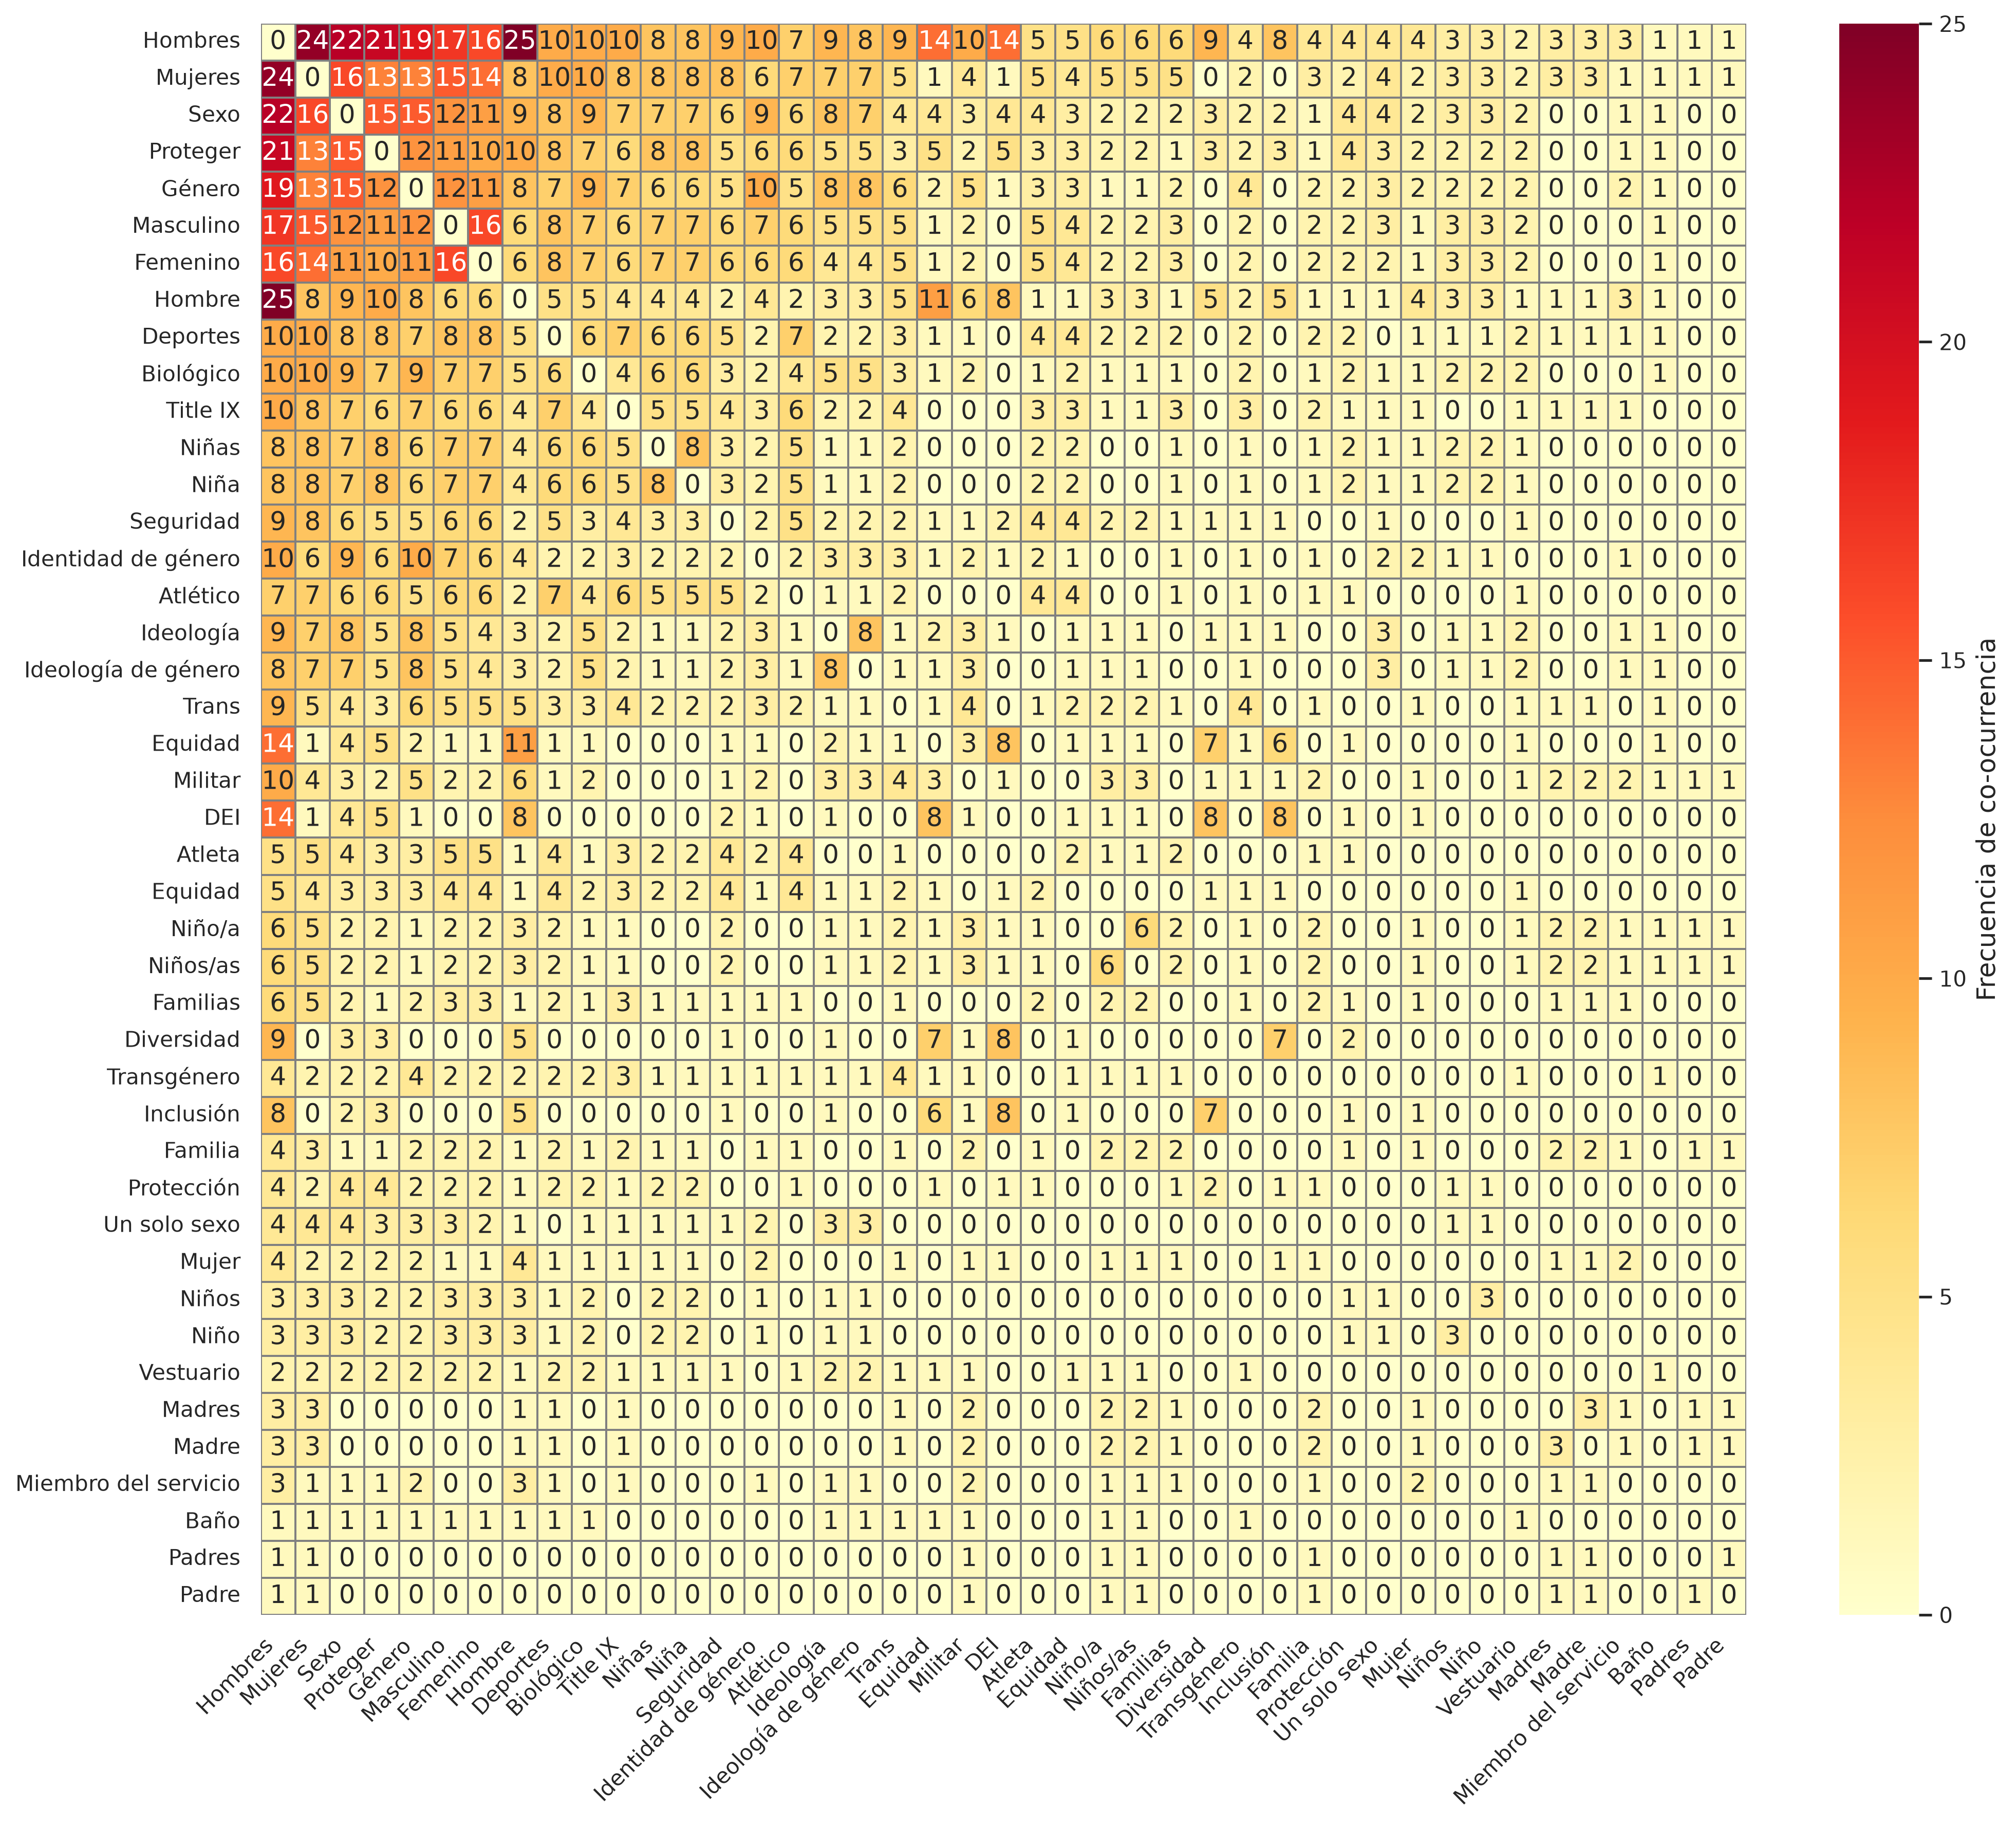

Exportado: c:\Users\qluis\Documents\Proyectos\voxitech\outputs\analisis\notebook\figura_06_matriz_coocurrencia.png
Términos en la matriz: 43
Co-ocurrencias totales (suma superior): 2019


In [37]:

# --- Figura 6: Matriz de co-ocurrencia (heatmap literal de la red) ---

from collections import defaultdict

key_terms = [
    "women", "woman", "men", "man", "girls", "girl", "boys", "boy",
    "female", "male", "sex", "gender", "gender identity", "biological",
    "family", "families", "mother", "mothers", "father", "fathers",
    "sports", "athletic", "athlete", "title ix",
    "transgender", "trans", "ideology", "gender ideology",
    "single-sex", "single sex spaces", "bathroom", "locker room",
    "protection", "protect", "children", "child", "safety", "fairness",
    "dei", "diversity", "equity", "inclusion", "military", "service member"
]

key_terms_lower = [t.lower() for t in key_terms]

# Matriz de co-ocurrencia
co_matrix = pd.DataFrame(0, index=key_terms_lower, columns=key_terms_lower, dtype=int)

for _, row in units_df.iterrows():
    text = row["text"].lower()
    present_terms = [t for t in key_terms_lower if t in text]
    for i in range(len(present_terms)):
        for j in range(i + 1, len(present_terms)):
            t1, t2 = sorted([present_terms[i], present_terms[j]])
            co_matrix.loc[t1, t2] += 1
            co_matrix.loc[t2, t1] += 1  # simétrica

# Filtrar términos que nunca co-ocurren para claridad visual
row_sums = co_matrix.sum(axis=1)
active_terms = row_sums[row_sums > 0].index.tolist()
co_matrix_active = co_matrix.loc[active_terms, active_terms]

# Ordenar por frecuencia total descendente
term_order = co_matrix_active.sum(axis=1).sort_values(ascending=False).index
co_matrix_active = co_matrix_active.loc[term_order, term_order]

# Etiquetas legibles para el heatmap
term_labels = {
    "women": "Mujeres", "woman": "Mujer", "men": "Hombres", "man": "Hombre",
    "girls": "Niñas", "girl": "Niña", "boys": "Niños", "boy": "Niño",
    "female": "Femenino", "male": "Masculino", "sex": "Sexo", "gender": "Género",
    "gender identity": "Identidad de género", "biological": "Biológico",
    "family": "Familia", "families": "Familias", "mother": "Madre", "mothers": "Madres",
    "father": "Padre", "fathers": "Padres", "sports": "Deportes", "athletic": "Atlético",
    "athlete": "Atleta", "title ix": "Title IX", "transgender": "Transgénero",
    "trans": "Trans", "ideology": "Ideología", "gender ideology": "Ideología de género",
    "single-sex": "Un solo sexo", "single sex spaces": "Espacios de un solo sexo",
    "bathroom": "Baño", "locker room": "Vestuario", "protection": "Protección",
    "protect": "Proteger", "children": "Niños/as", "child": "Niño/a",
    "safety": "Seguridad", "fairness": "Equidad", "dei": "DEI",
    "diversity": "Diversidad", "equity": "Equidad", "inclusion": "Inclusión",
    "military": "Militar", "service member": "Miembro del servicio"
}

labels = [term_labels.get(t, t) for t in co_matrix_active.index]

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    co_matrix_active.values,
    xticklabels=labels,
    yticklabels=labels,
    cmap="YlOrRd",
    annot=True,
    fmt="d",
    linewidths=0.5,
    linecolor="gray",
    cbar_kws={"label": "Frecuencia de co-ocurrencia"},
    ax=ax,
)
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=10)
ax.set_yticklabels(labels, fontsize=10)
plt.tight_layout()

fig_path = OUTPUTS_NOTEBOOK / "figura_06_matriz_coocurrencia.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print("Exportado:", fig_path)
print(f"Términos en la matriz: {len(active_terms)}")
print(f"Co-ocurrencias totales (suma superior): {int(co_matrix_active.values.sum() / 2)}")



## Figure 7. Co-occurrence flow diagram (Sankey)

This diagram represents the co-occurrence network as **elastic bands with source and target**. Each band represents a pair of terms that appear together in the same unit of analysis; the band thickness is proportional to the co-occurrence frequency.

**How to read the Sankey:** When you hover over a term (node) or a co-occurrence band (link), a number appears. That number indicates how many times the two connected terms appeared together in the same unit of analysis. It is calculated by counting, across all 51 units of analysis, every time both terms of the pair are present in the same text segment. For example, if "men" and "women" co-occur in 24 units, the link between them shows 24.

Unlike the heatmap (Figure 6), the Sankey lets you visually trace the **semantic flow** from one concept to another, revealing the association chains in the discourse (e.g., how *gender* connects to *ideology*, and how *women* connects to *sports*).


In [38]:

# --- Figure 7: Sankey co-occurrence diagram (source → target bands) ---

import plotly.graph_objects as go
from collections import defaultdict

key_terms = [
    "women", "woman", "men", "man", "girls", "girl", "boys", "boy",
    "female", "male", "sex", "gender", "gender identity", "biological",
    "family", "families", "mother", "mothers", "father", "fathers",
    "sports", "athletic", "athlete", "title ix",
    "transgender", "trans", "ideology", "gender ideology",
    "single-sex", "single sex spaces", "bathroom", "locker room",
    "protection", "protect", "children", "child", "safety", "fairness",
    "dei", "diversity", "equity", "inclusion", "military", "service member"
]

key_terms_lower = [t.lower() for t in key_terms]

# Count co-occurrences source→target (bidirectional)
co_pairs = defaultdict(int)

for _, row in units_df.iterrows():
    text = row["text"].lower()
    present_terms = [t for t in key_terms_lower if t in text]
    for i in range(len(present_terms)):
        for j in range(i + 1, len(present_terms)):
            t1, t2 = present_terms[i], present_terms[j]
            co_pairs[(t1, t2)] += 1
            co_pairs[(t2, t1)] += 1

# Sort by weight and take top N flows for visual clarity
sorted_pairs = sorted(co_pairs.items(), key=lambda x: x[1], reverse=True)
top_n = 40
top_pairs = sorted_pairs[:top_n]

print(f"Total co-occurrence pairs: {len(co_pairs)}")
print(f"Bands shown (top {top_n}): {len(top_pairs)}")

# Build unique node list
all_nodes = list(dict.fromkeys(
    [t for pair in top_pairs for t in pair[0]]
))
node_index = {node: i for i, node in enumerate(all_nodes)}

# English labels
term_labels = {
    "women": "Women", "woman": "Woman", "men": "Men", "man": "Man",
    "girls": "Girls", "girl": "Girl", "boys": "Boys", "boy": "Boy",
    "female": "Female", "male": "Male", "sex": "Sex", "gender": "Gender",
    "gender identity": "Gender identity", "biological": "Biological",
    "family": "Family", "families": "Families", "mother": "Mother", "mothers": "Mothers",
    "father": "Father", "fathers": "Fathers", "sports": "Sports", "athletic": "Athletic",
    "athlete": "Athlete", "title ix": "Title IX", "transgender": "Transgender",
    "trans": "Trans", "ideology": "Ideology", "gender ideology": "Gender ideology",
    "single-sex": "Single-sex", "single sex spaces": "Single-sex spaces",
    "bathroom": "Bathroom", "locker room": "Locker room", "protection": "Protection",
    "protect": "Protect", "children": "Children", "child": "Child",
    "safety": "Safety", "fairness": "Fairness", "dei": "DEI",
    "diversity": "Diversity", "equity": "Equity", "inclusion": "Inclusion",
    "military": "Military", "service member": "Service member"
}

node_labels = [term_labels.get(n, n) for n in all_nodes]

# Distinct color for every key node so threads are visually separable.
# The most important gender terms (Women, Men, Gender, Sex, Male, Female...)
# each get their own hue instead of sharing one red.
node_palette = {
    "women":      "rgba(231, 76, 60, 0.90)",   # red
    "woman":      "rgba(231, 76, 60, 0.90)",
    "men":        "rgba(52, 152, 219, 0.90)",   # blue
    "man":        "rgba(52, 152, 219, 0.90)",
    "gender":     "rgba(46, 204, 113, 0.90)",   # green
    "sex":        "rgba(230, 126, 34, 0.90)",   # orange
    "male":       "rgba(155, 89, 182, 0.90)",   # purple
    "female":     "rgba(232, 67, 147, 0.90)",   # pink
    "girls":      "rgba(241, 196, 15, 0.90)",   # yellow
    "girl":       "rgba(241, 196, 15, 0.90)",
    "boys":       "rgba(52, 73, 94, 0.90)",     # dark blue-gray
    "boy":        "rgba(52, 73, 94, 0.90)",
    "gender identity": "rgba(142, 68, 173, 0.90)", # violet
    "transgender":     "rgba(26, 188, 156, 0.90)", # turquoise
    "trans":           "rgba(26, 188, 156, 0.90)",
    "family":          "rgba(243, 156, 18, 0.90)", # amber-orange
    "families":        "rgba(243, 156, 18, 0.90)",
    "mother":          "rgba(230, 126, 34, 0.80)",
    "mothers":         "rgba(230, 126, 34, 0.80)",
    "father":          "rgba(52, 152, 219, 0.80)",
    "fathers":         "rgba(52, 152, 219, 0.80)",
    "children":        "rgba(46, 204, 113, 0.80)",
    "child":           "rgba(46, 204, 113, 0.80)",
    "sports":          "rgba(155, 89, 182, 0.85)",
    "athletic":        "rgba(155, 89, 182, 0.85)",
    "athlete":         "rgba(155, 89, 182, 0.85)",
    "title ix":        "rgba(155, 89, 182, 0.85)",
    "ideology":        "rgba(231, 76, 60, 0.75)",
    "gender ideology": "rgba(231, 76, 60, 0.75)",
    "dei":             "rgba(142, 68, 173, 0.85)",
    "diversity":       "rgba(142, 68, 173, 0.85)",
    "equity":          "rgba(142, 68, 173, 0.85)",
    "inclusion":       "rgba(142, 68, 173, 0.85)",
    "protection":      "rgba(26, 188, 156, 0.85)",
    "protect":         "rgba(26, 188, 156, 0.85)",
    "safety":          "rgba(26, 188, 156, 0.85)",
    "fairness":        "rgba(26, 188, 156, 0.85)",
    "biological":      "rgba(230, 126, 34, 0.80)",
}
default_color = "rgba(108, 117, 125, 0.80)"  # gray for others

node_colors = [node_palette.get(n, default_color) for n in all_nodes]

# Build arrays for Sankey
source = [node_index[pair[0][0]] for pair in top_pairs]
target = [node_index[pair[0][1]] for pair in top_pairs]
value = [pair[1] for pair in top_pairs]
max_val = max(value) if value else 1

# Link colors: inherit the source node color with transparency (so each thread
# is colored by its source category, not all gray)
# Links inherit the source node color (already in node_palette) with lower alpha.
base_colors = {k: v.replace("0.90)", "0.90)") for k, v in node_palette.items()}
# Adjust alpha for links: take each rgba and reduce the last channel to 0.30
def _link_alpha(color_str, alpha=0.30):
    # color_str like "rgba(231, 76, 60, 0.90)" -> replace last value
    import re
    return re.sub(r",\s*[\d.]+\)$", f", {alpha})", color_str)

default_color = "rgba(108, 117, 125, 0.30)"

# Build link color per source node
link_colors = []
for s_idx in source:
    src_node = all_nodes[s_idx]
    base = base_colors.get(src_node, default_color)
    link_colors.append(_link_alpha(base, 0.28))

fig = go.Figure(data=[go.Sankey(
    arrangement = "snap",
    node = dict(
        pad = 25,
        thickness = 30,
        line = dict(color="black", width=0.8),
        label = node_labels,
        color = node_colors,
    ),
    link = dict(
        source = source,
        target = target,
        value = value,
        color = link_colors,
        hovertemplate = "%{source.label} → %{target.label}: %{value} co-occurrences<extra></extra>",
    )
)])

fig.update_layout(
    font_size=12,
    font_family="Arial",
    width=1300,
    height=850,
    margin=dict(l=30, r=30, t=60, b=30),
)

# Export as static image
try:
    fig_path = OUTPUTS_NOTEBOOK / "figura_07_sankey_coocurrencia.png"
    fig.write_image(str(fig_path), scale=2)
    print("Exported (PNG):", fig_path)
except Exception as e:
    print("Could not export PNG:", e)

fig.show()
print(f"Nodes: {len(all_nodes)}, Bands: {len(top_pairs)}")


Total co-occurrence pairs: 1152
Bands shown (top 40): 40
Exported (PNG): c:\Users\qluis\Documents\Proyectos\voxitech\outputs\analisis\notebook\figura_07_sankey_coocurrencia.png


Nodes: 10, Bands: 40



### Top 7 terms and relationships in the Sankey diagram

**7 terms with highest total co-occurrence:**

| Term | Total co-occurrences |
|------|---------------------|
| men | 365 |
| women | 248 |
| sex | 230 |
| protect | 208 |
| gender | 207 |
| male | 196 |
| female | 187 |

**7 relationships with highest co-occurrence frequency:**

| Relationship | Co-occurrences |
|--------------|----------------|
| Man ↔ Men | 25 |
| Men ↔ Women | 24 |
| Men ↔ Sex | 22 |
| Men ↔ Protect | 21 |
| Gender ↔ Men | 19 |
| Male ↔ Men | 17 |
| Sex ↔ Women | 16 |

*Values calculated across the 51 units of analysis. A co-occurrence counts when both terms appear in the same unit.*



## Análisis cualitativo e interpretación

A partir de las figuras generadas y las citas textuales presentadas, se pueden identificar los siguientes hallazgos del análisis de discurso:

1. **Centralidad del binario sexo/género.** El tema *género y sexo* es el más frecuente (263 menciones) y se articula en torno a la afirmación de una realidad biológica inmutable. Las citas 1 y 2 ilustran cómo se construye la oposición entre "realidad biológica" e "ideología de género".

2. **Los deportes como escenario político.** El tema *mujeres, hombres, niñas y niños* aparece frecuentemente asociado a *deportes*, como muestran las citas 3 y 4. El discurso presenta la participación de mujeres trans en deportes femeninos como una amenaza a la equidad y la seguridad.

3. **La familia y la protección infantil.** El tema *infancia y protección* se vincula con narrativas sobre la protección de los niños contra la "ideología de género", como se observa en el comunicado de junio de 2026 (cita 5).

4. **Diferencias de énfasis por tipo de documento.** Las órdenes ejecutivas (enero-febrero 2025) contienen definiciones jurídicas detalladas, mientras que las proclamas (marzo 2025-2026) adoptan un tono más celebrativo y la comunica de junio 2026 se enmarca en un logro judicial.

5. **Voces femeninas en el discurso.** La declaración de la Primera Dama Melania Trump (cita 6) introduce un registro más afectivo centrado en la maternidad, diferenciándose del tono jurídico y confrontativo de las órdenes ejecutivas presidenciales.

Estos hallazgos constituyen la base cualitativa para el reporte académico (Fase 8) y el dashboard interactivo (Fase opcional).



## Referencias

### Fuentes primarias (corpus analizado)

The White House. (2025a, January 20). *Defending women from gender ideology extremism and restoring biological truth to the Federal Government* [Executive order]. https://www.whitehouse.gov/presidential-actions/2025/01/defending-women-from-gender-ideology-extremism-and-restoring-biological-truth-to-the-federal-government/

The White House. (2025b, February 5). *Keeping men out of women's sports* [Executive order]. https://www.whitehouse.gov/presidential-actions/2025/02/keeping-men-out-of-womens-school-sports/

The White House. (2025c, January 22). *Fact sheet: President Donald J. Trump protects civil rights and merit-based opportunity by ending illegal DEI* [Fact sheet]. https://www.whitehouse.gov/fact-sheets/2025/01/president-donald-j-trump-protects-civil-rights-and-merit-based-opportunity-by-ending-illegal-dei/

The White House. (2025d, January 27). *Fact sheet: President Donald J. Trump ensures military excellence and readiness* [Fact sheet]. https://www.whitehouse.gov/fact-sheets/2025/01/president-donald-j-trump-ensures-military-excellence-and-readiness/

The White House. (2025e, January 28). *Prioritizing military excellence and readiness* [Executive order]. https://www.whitehouse.gov/presidential-actions/2025/01/prioritizing-military-excellence-and-readiness/

The White House. (2025f, January 20). *Ending radical and wasteful government DEI programs and preferencing* [Executive order]. https://www.whitehouse.gov/presidential-actions/2025/01/ending-radical-and-wasteful-government-dei-programs-and-preferencing/

The White House. (2025g, January 21). *Ending illegal discrimination and restoring merit-based opportunity* [Executive order]. https://www.whitehouse.gov/presidential-actions/2025/01/ending-illegal-discrimination-and-restoring-merit-based-opportunity/

The White House. (2025h, March 18). *Fact sheet: President Donald J. Trump removes DEI from the Foreign Service* [Fact sheet]. https://www.whitehouse.gov/fact-sheets/2025/03/president-donald-j-trump-removes-dei-from-the-foreign-service/

The White House. (2025i, March 6). *Women's History Month, 2025* [Proclamation]. https://www.whitehouse.gov/presidential-actions/2025/03/womens-history-month-2025/

The White House. (2025j, May 8). *First Lady Melania Trump reflects on the strength of motherhood during White House Military Mothers Celebration* [Remarks]. https://www.whitehouse.gov/briefings-statements/2025/05/first-lady-melania-trump-reflects-strength-motherhood-during-white-house-military-mothers-celebration/

The White House. (2026a, March 12). *Women's History Month, 2026* [Proclamation]. https://www.whitehouse.gov/presidential-actions/2026/03/womens-history-month-2026/

The White House. (2026b, June 30). *Supreme Court bolsters President Trump's push to eliminate transgender insanity* [Release]. https://www.whitehouse.gov/releases/2026/06/supreme-court-bolsters-president-trumps-push-to-eliminate-transgender-insanity/

### Referencias metodológicas

Fairclough, N. (1995). *Critical discourse analysis: The critical study of language*. Longman.

Foucault, M. (1971). *Orders of discourse*. In *Social Science Information*, 10(2), 7-30.

American Psychological Association. (2020). *Publication manual of the American Psychological Association* (7th ed.). APA.

---
*Notebook generado por VoxiTech Lab AI. Todas las figuras fueron exportadas a `outputs/analisis/notebook/` con alta resolución (300 dpi) para publicaciones académicas. Los datos subyacentes provienen del corpus real de whitehouse.gov procesado por el pipeline del proyecto.*
